In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data/penguins.csv', sep=',')
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
df.isna().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

In [3]:
datas = df.dropna() # 丢弃缺失值
datas.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [6]:
datas.isna().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [7]:
datas = datas.iloc[:, :-1]
datas.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [8]:
datas = (datas - datas.min())/(datas.max() - datas.min()) # min-max归一化
datas.min(), datas.max()

(culmen_length_mm     0.0
 culmen_depth_mm      0.0
 flipper_length_mm    0.0
 body_mass_g          0.0
 dtype: float64,
 culmen_length_mm     1.0
 culmen_depth_mm      1.0
 flipper_length_mm    1.0
 body_mass_g          1.0
 dtype: float64)

In [9]:
rc = {'font.family':'SimHei', 'axes.unicode_minus':False}
sns.set(font_scale=0.9, rc=rc)

In [10]:
corr_matrix = datas.corr()
corr_matrix

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000000,-0.229465,0.021238,0.588891
culmen_depth_mm,-0.229465,1.000000,0.045725,-0.471071
flipper_length_mm,0.021238,0.045725,1.000000,0.048323
body_mass_g,0.588891,-0.471071,0.048323,1.000000


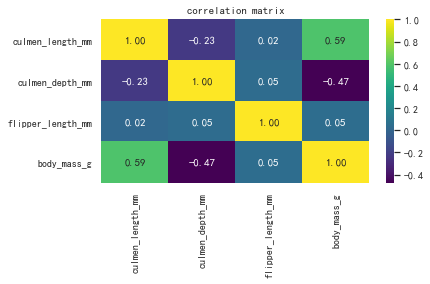

In [13]:
plt.figure(figsize=(6, 3))
sns.heatmap(corr_matrix, annot=True, cmap='viridis', fmt='.2f')
plt.title('correlation matrix')
plt.show()

In [14]:
from sklearn.decomposition import PCA

In [23]:
df.loc[df['sex']=='MALE', 'sex'] = 0
df.loc[df['sex']=='.', 'sex'] = 0
df.loc[df['sex']=='FEMALE', 'sex'] = 1

In [24]:
df.sex

0      0
1      1
2      1
4      1
5      0
      ..
338    1
340    1
341    0
342    1
343    0
Name: sex, Length: 335, dtype: object

In [22]:
pca_data = df.dropna()

In [26]:
pca_data = (pca_data - pca_data.min()) / (pca_data.max() - pca_data.min())

In [29]:
pca = PCA(n_components=3, random_state=57)
X_3d = pca.fit_transform(pca_data)
X_3d.shape

(335, 3)

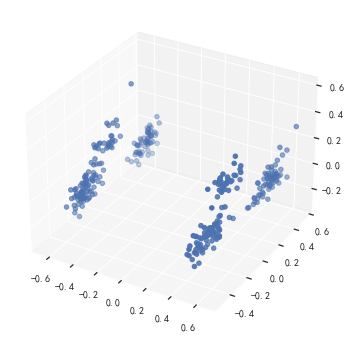

In [30]:
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor('white')
ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2])
plt.show()